# NumPy 4: Copias y vistas

_Autor: Thomas Gonzalez_


Este notebook muestra por qué cambiar un recorte de un array puede cambiar el array original, cómo comprobarlo y cómo evitarlo. Cubre:

1. Vistas: una ventana al mismo cubo
2. Copias: un array nuevo e independiente
3. El error en un caso real: restar el fondo y dañar el cubo
4. Por qué existen las vistas: casi gratis

Este notebook asume los notebooks de NumPy 1, 2 y 3 (qué es un array, `np.load`, forma, `dtype` e indexación).

---

### Prompts de profundización

Al final de cada tema hay unos prompts para que los usen con su chatbot de confianza y profundicen más.

## 0. Prerrequisitos

Para correr este notebook, deben asegurarse de haber creado el virtual environment de python siguiendo las instrucciones del README. Una vez creado, selecciona el kernel del notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Para instalar python, el manejador de paquetes UV, los ambientes de conda y configurar Visual Studio Code para correr y editar Jupyter Notebooks en él, revisen los siguientes recursos:

- [Cómo instalar Anaconda y Jupyter](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [Instalación de UV](https://youtu.be/TJor7z8g8FA?si=QT2XVKeC29dYyDts)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

## 1. Vistas: una ventana al mismo cubo

Cargamos las fotos y la máscara de la estrella.

In [1]:
import numpy as np

cube = np.load("../data/flux_cube.npy")
mask = np.load("../data/aperture_mask.npy")

En el video 3, cambiar `box` cambió el cubo. `np.shares_memory` comprueba si dos arrays usan la misma memoria, sin tener que cambiar nada:

In [2]:
#recordando del video 3
cube_2 = np.load("../data/flux_cube.npy")
print(cube_2[0, 5, 5])
box = cube_2[0, 4:7, 4:7]
box[1, 1] = 0

print(cube_2[0, 5, 5])

7896.526
0.0


In [3]:
np.shares_memory(cube_2,box)

True

Los demás recortes con números y rangos del video 3: una foto, las primeras 170 fotos y la historia de un píxel.

In [6]:
frame = cube[0]
early = cube[:170]
pixel = cube[:,5,5]

print(np.shares_memory(cube,frame))
print(np.shares_memory(cube,early))
print(np.shares_memory(cube,pixel))

True
True
True


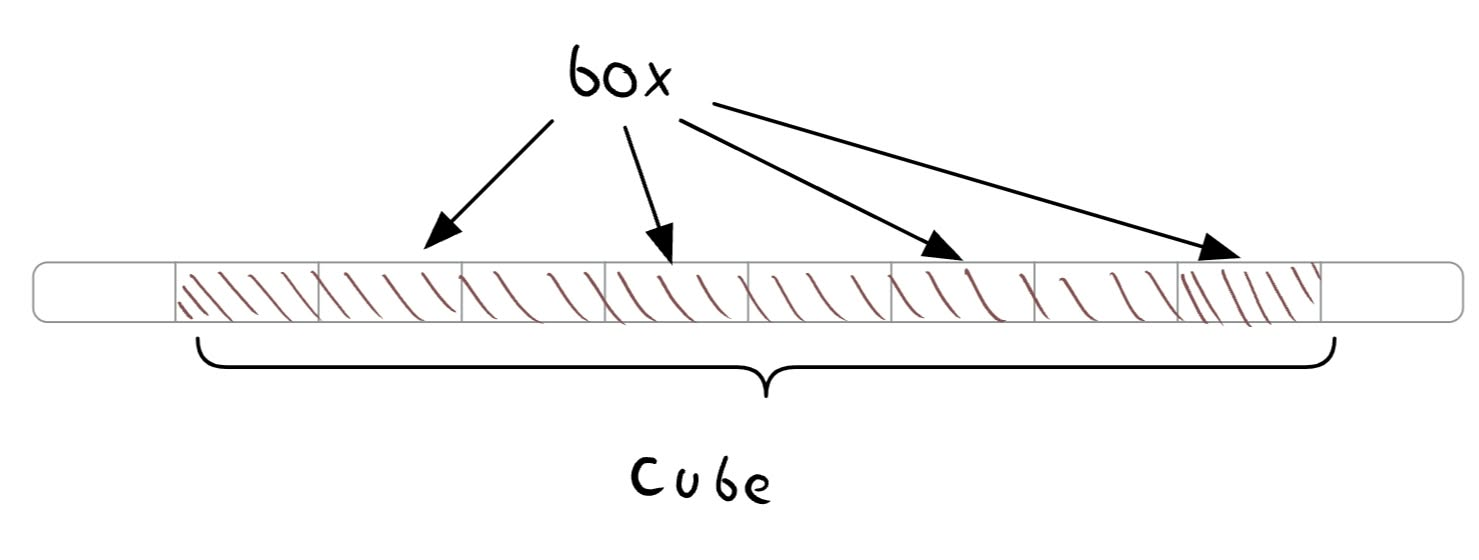

**Prompts de profundización:**

- `¿Qué es una vista (view) en NumPy y en qué se diferencia de una copia?`
- `¿Cómo puede cube[:, 5, 5] ser una vista si sus números no están uno al lado del otro en la memoria?`
- `¿Qué hace np.shares_memory y qué diferencia tiene con np.may_share_memory?`

## 2. Copias: un array nuevo e independiente

Indexar con la máscara (video 3) y cambiar el tipo con `astype` (video 2):

In [7]:
#estrella con la mascara
star = frame[mask]
#estrella con 64 bits
cube64 = cube.astype(np.float64)

print(np.shares_memory(star, cube))
print(np.shares_memory(cube64, cube))

False
False


Con `.copy()` se pide una copia a propósito. Repetimos el cierre del video 3:

In [8]:
#recordando del video 3
cube_2 = np.load("../data/flux_cube.npy")
box = cube_2[0, 4:7, 4:7].copy()
box[1, 1] = 0

print(np.shares_memory(box, cube_2))
print(cube_2[0, 5, 5])

False
7896.526


**Prompts de profundización:**

- `¿Por qué indexar un array de NumPy con una máscara booleana siempre crea una copia?`
- `¿Qué diferencia hay entre arr.copy() y np.copy(arr) en NumPy?`
- `¿Qué otras operaciones de NumPy devuelven una vista y cuáles una copia?`

## 3. El error en un caso real: restar el fondo y dañar el cubo

Cada píxel trae, además de la luz de la estrella, unos 80 de luz del fondo del cielo. En la esquina de la primera foto casi solo hay fondo:

In [9]:
print(cube[0, 0, 0])

80.09261


Le restamos 80 a cada número de las primeras 170 fotos (`early`, de la sección 1):

In [10]:
early -= 80

`early` era una vista: el cubo cambió. Pero solo en las primeras 170 fotos:

In [11]:
cube[:,0,0]

array([ 9.2613220e-02,  1.0100174e+00, -1.1123352e+00, ...,
        9.2354774e+01,  9.2803505e+01,  8.9972969e+01],
      shape=(1440,), dtype=float32)

La solución: volver a cargar el cubo y restarle el fondo a una copia.

In [14]:
cube = np.load("../data/flux_cube.npy")

early = cube[:170].copy()
early -= 80

cube[:,0,0]

array([80.09261 , 81.01002 , 78.887665, ..., 92.354774, 92.803505,
       89.97297 ], shape=(1440,), dtype=float32)

**Prompts de profundización:**

- `¿Por qué en NumPy arr -= 80 modifica el array original y arr = arr - 80 no?`
- `¿Qué es el fondo del cielo en una imagen astronómica y por qué hay que restarlo?`
- `¿Cómo evito modificar sin querer los datos originales cuando trabajo con NumPy?`

## 4. Por qué existen las vistas: casi gratis

Cuánto tarda una vista de una foto:

In [15]:
%%timeit
_ = cube[10]

37.4 ns ± 0.186 ns per loop (mean ± std. dev. of 7 runs, 10,000,000 loops each)


Y una copia:

In [18]:
%%timeit
_ = cube[10].copy()

157 ns ± 0.27 ns per loop (mean ± std. dev. of 7 runs, 10,000,000 loops each)


**Prompts de profundización:**

- `¿Por qué crear una vista en NumPy no depende del tamaño del array?`
- `¿Cuándo conviene hacer una copia en NumPy aunque cueste más memoria y tiempo?`
- `¿Qué es el copy-on-write de Pandas y qué problema de vistas y copias resuelve?`
- `¿Como se puede liberar la memoria de una variable que no estés usando y que otras formas hay de ahorrar memoria?`

## 5. ¿Qué viene?

La tabla del video 3, con las primeras 170 fotos: una fila por foto, una columna por píxel de la estrella. La sumamos:

In [22]:
table = cube[:170, mask]

print(np.sum(table))

8.175907e+06
